# **INTEGRANDES**
*   **Dady Sneider Loaiza Loaiza**
*   **Martín Santiago pinzón Quiceno**



In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy import optimize
from scipy.special import gammaln  # log de la funcion gamma (C2)
import os

C1 = 1106891817 + 1141318622
C2 = 1011099583
S = C1 + C2

In [6]:
pd.set_option("display.width", 140)  # tablas mas anchas al imprimir
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

C1 = 1106891817 + 1141318622  # suma de las dos cedulas del primer bloque
C2 = 1011099583
S = C1 + C2  # semilla y base de todos los parametros

tau = 180 + 10 * (S % 9)  # umbral del SLO en ms
epsilon = 0.01 * (1 + S % 3)  # proporcion maxima tolerada de L > tau
niveles = {0: 0.90, 1: 0.95, 2: 0.99}
confianza = niveles[S % 3]  # nivel 1 - alpha
alpha = 1 - confianza
g = 1.4 + 0.1 * (S % 7)  # factor de crecimiento de la tasa
t1 = 80 + 10 * (S % 5)  # frontera pequena / mediana en KB
t2 = 400 + 25 * (S % 5)  # frontera mediana / grande en KB
pi_prod = (4 + S % 6) / 1000  # prevalencia de incidentes en produccion
k_max = 4 + (S % 5)  # falsas alarmas maximas por dia
r = S % 6  # desplazamiento para B4
N = 10 + (S % 11)  # solicitudes consecutivas para C4

rng = np.random.default_rng(S)

In [7]:
parametros = pd.DataFrame({
    "parametro": ["S", "tau (ms)", "epsilon", "1 - alpha", "g", "t1 (KB)", "t2 (KB)", "pi", "k_max", "r", "N"],
    "valor": [str(S), str(tau), str(round(epsilon, 2)), str(confianza), str(round(g, 1)), str(t1), str(t2),
              str(pi_prod), str(k_max), str(r), str(N)],  # como texto para que no salga en notacion cientifica
})
print(parametros.to_string(index=False))

parametro      valor
        S 3259310022
 tau (ms)        180
  epsilon       0.01
1 - alpha        0.9
        g        1.7
  t1 (KB)        100
  t2 (KB)        450
       pi      0.004
    k_max          6
        r          0
        N         11


# Parte A — Auditoría y preparación de los datos

## A1. Auditoría de `solicitudes.csv`

Revisamos cada columna desde la lógica del sistema: una solicitud con caché no usa GPU, la latencia no puede ser menor que red + GPU (la espera en cola es mayor o igual a cero), los intentos van de 1 a 3 y una solicitud solo puede fallar si agotó los 3 intentos. También buscamos duplicados, nulos, valores negativos y valores fuera de escala. Primero contamos cada problema sobre los datos crudos.

In [8]:
crudos = pd.read_csv("solicitudes.csv")  # datos tal como llegan
print("filas crudas:", len(crudos))
print(crudos.head())
print()
print("nulos por columna:")
print(crudos.isna().sum())

filas crudas: 40951
   id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  latencia_ms  intentos  exito
0             1       0.0822  308.08          0       A   13.77   49.45        63.22         1      1
1             2       0.1876  827.28          1       B   19.56    0.00        19.56         1      1
2             3       0.2032  608.65          0       B   20.98   23.39        44.37         1      1
3             4       0.2169  278.76          0       A   21.91   30.20        52.10         1      1
4             5       0.2267   84.03          1       A   20.71    0.00        20.71         1      1

nulos por columna:
id_solicitud     0
t_llegada_s      0
tam_kb           0
cache_hit        0
version          0
red_ms          41
gpu_ms          40
latencia_ms      0
intentos         0
exito            0
dtype: int64


In [9]:
duplicados_exactos = crudos.duplicated().sum()  # filas identicas en todas las columnas
ids_repetidos = crudos["id_solicitud"].duplicated().sum()  # ids que aparecen mas de una vez
print("filas duplicadas exactas:", duplicados_exactos)
print("ids repetidos:", ids_repetidos)

conteo_ids = crudos["id_solicitud"].value_counts()
ids_con_copia = conteo_ids[conteo_ids > 1].index
ids_de_exactos = set(crudos[crudos.duplicated(keep=False)]["id_solicitud"])
ids_raros = [i for i in ids_con_copia if i not in ids_de_exactos]  # id repetido pero con filas distintas
print("ids repetidos que no son copia exacta:", ids_raros)
print(crudos[crudos["id_solicitud"].isin(ids_raros)])

filas duplicadas exactas: 121
ids repetidos: 122
ids repetidos que no son copia exacta: [21359]
       id_solicitud  t_llegada_s  tam_kb  cache_hit version  red_ms  gpu_ms  latencia_ms  intentos  exito
21416         21359     718.3461  193.45          0       A    12.8     NaN       136.97         1      1
21417         21359     718.3461  193.45          0       A    12.8   14.97       136.97         1      1


In [10]:
print("latencia negativa:", (crudos["latencia_ms"] < 0).sum())
print("valores de latencia negativa:", crudos.loc[crudos["latencia_ms"] < 0, "latencia_ms"].unique())
print("red negativa:", (crudos["red_ms"] < 0).sum())
print("gpu negativa:", (crudos["gpu_ms"] < 0).sum())
print("tam_kb <= 0:", (crudos["tam_kb"] <= 0).sum())
print("gpu > 0 con cache_hit = 1:", ((crudos["gpu_ms"] > 0) & (crudos["cache_hit"] == 1)).sum())
print("gpu = 0 con cache_hit = 0:", ((crudos["gpu_ms"] == 0) & (crudos["cache_hit"] == 0)).sum())
print("intentos fuera de 1..3:", (~crudos["intentos"].isin([1, 2, 3])).sum())
print("tiempos de llegada fuera de [0, 1200]:", ((crudos["t_llegada_s"] < 0) | (crudos["t_llegada_s"] > 1200)).sum())
print("llegadas desordenadas:", (crudos["t_llegada_s"].diff() < 0).sum())
print()
print("tabla intentos vs exito:")
print(pd.crosstab(crudos["intentos"], crudos["exito"]))

latencia negativa: 122
valores de latencia negativa: [-1.]
red negativa: 0
gpu negativa: 0
tam_kb <= 0: 0
gpu > 0 con cache_hit = 1: 0
gpu = 0 con cache_hit = 0: 0
intentos fuera de 1..3: 0
tiempos de llegada fuera de [0, 1200]: 0
llegadas desordenadas: 0

tabla intentos vs exito:
exito       0      1
intentos            
1           0  34209
2           0   5491
3         242   1009


In [11]:
tamanos_ordenados = np.sort(crudos["tam_kb"].values)
print("los 70 tamanos mas grandes:")
print(tamanos_ordenados[-70:].round(1))  # se ve el salto entre ~1600 y ~17000

limite_tam = 5000  # hay un hueco enorme entre ~1600 y ~17000 KB
grandes = crudos[crudos["tam_kb"] > limite_tam]
print("filas con tam_kb > 5000:", len(grandes))
print("mayor tamano normal:", crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"].max())
print("menor tamano anomalo:", grandes["tam_kb"].min())
print()
print("cuantiles de los anomalos divididos por 1024:")
print((grandes["tam_kb"] / 1024).quantile([0, 0.25, 0.5, 0.75, 1]).round(1))
print("cuantiles de los tamanos normales:")
print(crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"].quantile([0, 0.25, 0.5, 0.75, 1]).round(1))
prueba_ks = stats.ks_2samp(grandes["tam_kb"] / 1024, crudos.loc[crudos["tam_kb"] <= limite_tam, "tam_kb"])
print("KS entre anomalos/1024 y normales: estadistico =", round(prueba_ks.statistic, 3), " p =", round(prueba_ks.pvalue, 3))

los 70 tamanos mas grandes:
[   1269.2    1277.4    1281.5    1288.4    1296.6    1317.8    1351.6
    1396.2    1566.8   17162.2   18606.1   18821.1   40038.4   46489.6
   50288.6   62648.3   85043.2   91658.2   97361.9  121630.7  124129.3
  130252.8  130273.3  131532.8  137502.7  139786.2  141148.2  147425.3
  148377.6  149575.7  151081.   156723.2  156835.8  160983.   161085.4
  161116.2  170690.6  173649.9  175226.9  175851.5  177950.7  203192.3
  213749.8  218204.2  220303.4  226795.5  231977.   239493.1  247275.5
  258897.9  266025.   271953.9  280811.5  282593.3  289003.5  292628.5
  299182.1  315637.8  317829.1  320327.7  374681.6  376350.7  411545.6
  481976.3  498452.5  508825.6  510699.5  679936.   719155.2 1015705.6]
filas con tam_kb > 5000: 61
mayor tamano normal: 1566.78
menor tamano anomalo: 17162.24

cuantiles de los anomalos divididos por 1024:
0.00     16.8
0.25    134.3
0.50    171.7
0.75    282.2
1.00    991.9
Name: tam_kb, dtype: float64
cuantiles de los tamanos no

Los 61 tamaños gigantes, divididos por 1024, caen en el mismo rango que los tamaños normales y la prueba KS no distingue las dos distribuciones. La explicación física más simple es que esas filas se registraron en bytes en lugar de KB, así que los corregimos dividiendo por 1024 en vez de borrarlos.

Ahora revisamos la ecuación de latencia: L = red + espera + G, con espera mayor o igual a 0. Como los datos están redondeados a 0,01 ms, usamos una tolerancia de 0,02 ms.

In [12]:
tolerancia = 0.02  # ms, por el redondeo a dos decimales
residuo = crudos["latencia_ms"] - crudos["red_ms"] - crudos["gpu_ms"]  # esto deberia ser la espera en cola
latencia_valida = crudos["latencia_ms"] > 0
imposibles = latencia_valida & (residuo < -tolerancia)
print("filas con latencia < red + gpu (fuera de tolerancia):", imposibles.sum())
print("de esas, con cache_hit = 1:", (imposibles & (crudos["cache_hit"] == 1)).sum())
print("faltante de latencia en esas filas (ms):")
print(residuo[imposibles].describe().round(2))
print("filas con residuo entre -0.02 y 0 (solo redondeo):", (latencia_valida & (residuo < 0) & (residuo >= -tolerancia)).sum())

filas con latencia < red + gpu (fuera de tolerancia): 80
de esas, con cache_hit = 1: 28
faltante de latencia en esas filas (ms):
count     80.00
mean     -19.80
std       19.45
min     -134.98
25%      -21.85
50%      -14.50
75%       -9.70
max       -3.58
dtype: float64
filas con residuo entre -0.02 y 0 (solo redondeo): 4796


In [13]:
print("nulos de gpu_ms segun cache_hit:")
print(pd.crosstab(crudos["gpu_ms"].isna(), crudos["cache_hit"]))
print("nulos de red_ms segun cache_hit:")
print(pd.crosstab(crudos["red_ms"].isna(), crudos["cache_hit"]))
print("latencia = -1 segun exito:")
print(pd.crosstab(crudos["latencia_ms"] < 0, crudos["exito"]))

nulos de gpu_ms segun cache_hit:
cache_hit      0      1
gpu_ms                 
False      25951  14960
True          24     16
nulos de red_ms segun cache_hit:
cache_hit      0      1
red_ms                 
False      25946  14964
True          29     12
latencia = -1 segun exito:
exito          0      1
latencia_ms            
False        242  40587
True           0    122


Con lo encontrado aplicamos los tratamientos. La regla general es: **no borrar una solicitud que sí ocurrió**, porque las llegadas, los intentos y la caché siguen siendo información válida aunque otra columna esté mal. Solo se borran las copias (filas que no son solicitudes nuevas). Cuando un valor es imposible y no sabemos cuál de las columnas está mal, se marca como faltante (NaN) solo esa columna.

In [14]:
datos = crudos.copy()
filas_iniciales = len(datos)

datos = datos.drop_duplicates()  # 1. quitar copias exactas
quitadas_exactas = filas_iniciales - len(datos)

fila_incompleta = datos["id_solicitud"].isin(ids_raros) & datos["gpu_ms"].isna()  # 2. copia del id repetido sin gpu
datos = datos[~fila_incompleta]
quitadas_id = fila_incompleta.sum()

centinela = datos["latencia_ms"] < 0  # 3. latencia = -1 es un codigo de "no medido"
datos.loc[centinela, "latencia_ms"] = np.nan

en_bytes = datos["tam_kb"] > limite_tam  # 4. tamanos registrados en bytes
datos.loc[en_bytes, "tam_kb"] = datos.loc[en_bytes, "tam_kb"] / 1024

gpu_nula_cache = datos["gpu_ms"].isna() & (datos["cache_hit"] == 1)  # 5. con cache la gpu es 0 por definicion
datos.loc[gpu_nula_cache, "gpu_ms"] = 0.0
gpu_nula_sin_cache = datos["gpu_ms"].isna()  # 6. sin cache no se puede saber la gpu: se deja NaN
red_nula = datos["red_ms"].isna()  # 7. red faltante: se deja NaN

residuo = datos["latencia_ms"] - datos["red_ms"] - datos["gpu_ms"]
latencia_imposible = residuo < -tolerancia  # 8. latencia menor que red + gpu
datos.loc[latencia_imposible, "latencia_ms"] = np.nan

datos = datos.reset_index(drop=True)
print("filas finales:", len(datos))

filas finales: 40829


In [15]:
tabla_a1 = pd.DataFrame({
    "filas afectadas": [
        quitadas_exactas, quitadas_id, centinela.sum(), en_bytes.sum(),
        gpu_nula_cache.sum(), gpu_nula_sin_cache.sum(), red_nula.sum(), latencia_imposible.sum(), 0, 0, 0,
    ],
    "criterio": [
        "fila identica a otra en todas las columnas",
        "id repetido; una copia tiene gpu_ms nulo y la otra completa",
        "latencia_ms = -1 (codigo de 'no medido', no es un tiempo)",
        "tam_kb > 5000: hueco entre 1567 y 17162; /1024 coincide con la distribucion normal (KS)",
        "gpu_ms nulo con cache_hit = 1",
        "gpu_ms nulo con cache_hit = 0",
        "red_ms nulo",
        "latencia < red + gpu - 0.02 ms (espera en cola negativa)",
        "gpu_ms > 0 con cache_hit = 1, o gpu_ms = 0 sin cache",
        "intentos fuera de 1..3, o exito = 0 con menos de 3 intentos",
        "tiempos negativos o llegadas fuera de [0, 1200] s",
    ],
    "tratamiento": [
        "eliminar la copia",
        "conservar la fila completa",
        "latencia -> NaN; la solicitud se conserva para llegadas, intentos y gpu",
        "dividir tam_kb entre 1024 (estaba en bytes)",
        "imputar gpu_ms = 0 (por definicion del sistema)",
        "dejar NaN; se excluye solo en analisis de gpu",
        "dejar NaN; se excluye solo en analisis de red",
        "latencia -> NaN (no se sabe que columna fallo)",
        "ninguno (0 casos)",
        "ninguno (0 casos)",
        "ninguno (0 casos)",
    ],
})
print(tabla_a1.to_string(index=False))
print()
print("filas crudas:", filas_iniciales, " -> filas limpias:", len(datos))
print("latencias disponibles:", datos["latencia_ms"].notna().sum())

 filas afectadas                                                                                criterio                                                             tratamiento
             121                                              fila identica a otra en todas las columnas                                                       eliminar la copia
               1                             id repetido; una copia tiene gpu_ms nulo y la otra completa                                              conservar la fila completa
             122                               latencia_ms = -1 (codigo de 'no medido', no es un tiempo) latencia -> NaN; la solicitud se conserva para llegadas, intentos y gpu
              61 tam_kb > 5000: hueco entre 1567 y 17162; /1024 coincide con la distribucion normal (KS)                             dividir tam_kb entre 1024 (estaba en bytes)
              16                                                           gpu_ms nulo con cache_hit = 1           

**Conclusión A1.** Solo se eliminan las copias (122 filas), porque no son solicitudes nuevas e inflarían la tasa de llegadas. El resto de problemas se corrige (tamaños en bytes, GPU nula con caché) o se marca como faltante solo en la columna afectada. Las comprobaciones de coherencia entre caché y GPU, intentos y éxito, y tiempos de llegada no encontraron problemas.

## A2. ¿Un solo régimen en toda la ventana?

Si toda la ventana fuera un único proceso de Poisson, los conteos por intervalo tendrían varianza igual a la media (índice de dispersión 1). Lo probamos con la prueba de dispersión (chi-cuadrado). Después buscamos el segmento anómalo con un barrido de punto de cambio: probamos todos los pares (inicio, fin) y nos quedamos con el que maximiza la log-verosimilitud de un modelo con una tasa adentro y otra afuera.

In [16]:
ancho = 10  # segundos por intervalo
bordes = np.arange(0, 1200 + ancho, ancho)
conteos, _ = np.histogram(datos["t_llegada_s"], bins=bordes)  # llegadas por intervalo de 10 s

media_conteos = conteos.mean()
var_conteos = conteos.var(ddof=1)
indice_dispersion = var_conteos / media_conteos
estadistico_disp = (len(conteos) - 1) * indice_dispersion  # chi-cuadrado con k-1 grados de libertad
p_disp = stats.chi2.sf(estadistico_disp, df=len(conteos) - 1)
print("media de conteos por 10 s:", round(media_conteos, 1))
print("varianza:", round(var_conteos, 1))
print("indice de dispersion:", round(indice_dispersion, 2))
print("p-valor prueba de dispersion:", p_disp)

media de conteos por 10 s: 340.2
varianza: 19261.9
indice de dispersion: 56.61
p-valor prueba de dispersion: 0.0


El índice de dispersión es muy mayor que 1 y el p-valor es prácticamente 0, así que la ventana completa **no** es un solo proceso de Poisson. Ahora buscamos dónde está el cambio. Para un modelo de Poisson, la log-verosimilitud de un segmento con total T y m intervalos es T·log(T/m) − T (más una constante que no depende del corte). Para los reintentos usamos el mismo barrido con un modelo binomial.

In [17]:
def barrido_segmento(exitos, totales, modelo):
    # busca el par (i, j) que separa los intervalos i..j-1 del resto
    m = len(exitos)
    mejor = (-np.inf, 0, 0)
    for i in range(1, m):
        for j in range(i + 1, m + 1):
            dentro_e = exitos[i:j].sum()
            fuera_e = exitos.sum() - dentro_e
            dentro_n = totales[i:j].sum()
            fuera_n = totales.sum() - dentro_n
            if modelo == "poisson":
                ll = dentro_e * np.log(dentro_e / dentro_n) - dentro_e + fuera_e * np.log(fuera_e / fuera_n) - fuera_e
            else:
                p1 = dentro_e / dentro_n
                p2 = fuera_e / fuera_n
                ll = dentro_e * np.log(p1) + (dentro_n - dentro_e) * np.log(1 - p1) + fuera_e * np.log(p2) + (fuera_n - fuera_e) * np.log(1 - p2)
            if ll > mejor[0]:
                mejor = (ll, i, j)
    return mejor


def log_ver_un_regimen(exitos, totales, modelo):
    tot_e = exitos.sum()
    tot_n = totales.sum()
    if modelo == "poisson":
        return tot_e * np.log(tot_e / tot_n) - tot_e
    p = tot_e / tot_n
    return tot_e * np.log(p) + (tot_n - tot_e) * np.log(1 - p)

In [18]:
resultados_a2 = []
for ancho_prueba in [5, 10, 20]:
    bordes_prueba = np.arange(0, 1200 + ancho_prueba, ancho_prueba)
    llegadas, _ = np.histogram(datos["t_llegada_s"], bins=bordes_prueba)
    reintentos, _ = np.histogram(datos.loc[datos["intentos"] > 1, "t_llegada_s"], bins=bordes_prueba)

    ll, i, j = barrido_segmento(llegadas, np.ones(len(llegadas)), "poisson")  # tasa de llegadas
    razon = 2 * (ll - log_ver_un_regimen(llegadas, np.ones(len(llegadas)), "poisson"))
    resultados_a2.append(["llegadas (Poisson)", ancho_prueba, i * ancho_prueba, j * ancho_prueba, razon, stats.chi2.sf(razon, df=3)])

    ll, i, j = barrido_segmento(reintentos, llegadas, "binomial")  # proporcion de reintentos
    razon = 2 * (ll - log_ver_un_regimen(reintentos, llegadas, "binomial"))
    resultados_a2.append(["reintentos (binomial)", ancho_prueba, i * ancho_prueba, j * ancho_prueba, razon, stats.chi2.sf(razon, df=3)])

tabla_a2 = pd.DataFrame(resultados_a2, columns=["criterio", "ancho (s)", "inicio (s)", "fin (s)", "razon de verosimilitud", "p-valor aprox"])
print(tabla_a2.to_string(index=False))

             criterio  ancho (s)  inicio (s)  fin (s)  razon de verosimilitud  p-valor aprox
   llegadas (Poisson)          5         695      860             5397.291103   0.000000e+00
reintentos (binomial)          5         695      860              927.176011  1.127915e-200
   llegadas (Poisson)         10         690      860             5262.152312   0.000000e+00
reintentos (binomial)         10         690      860              917.056836  1.767051e-198
   llegadas (Poisson)         20         700      860             5232.359596   0.000000e+00
reintentos (binomial)         20         680      860              900.351306  7.427210e-195


La razón de verosimilitud compara "dos regímenes" contra "uno". Como los puntos de corte se eligen buscando el máximo, el p-valor chi-cuadrado (3 grados de libertad: dos cortes y una tasa extra) es solo aproximado, pero la razón es tan grande que la conclusión no cambia. Los seis criterios ubican el segmento anómalo prácticamente en el mismo lugar (entre ~690 y ~860 s), lo que muestra que la conclusión es poco sensible al ancho del intervalo y a la variable usada. Fijamos el criterio principal: llegadas con intervalos de 10 s.

In [19]:
fila_principal = tabla_a2[(tabla_a2["criterio"] == "llegadas (Poisson)") & (tabla_a2["ancho (s)"] == 10)]
inicio_anomalo = float(fila_principal["inicio (s)"].iloc[0])
fin_anomalo = float(fila_principal["fin (s)"].iloc[0])
print("segmento anomalo: [", inicio_anomalo, ",", fin_anomalo, ") s")

datos["regimen"] = "estable"
en_anomalo = (datos["t_llegada_s"] >= inicio_anomalo) & (datos["t_llegada_s"] < fin_anomalo)
datos.loc[en_anomalo, "regimen"] = "anomalo"
duracion_anomalo = fin_anomalo - inicio_anomalo
duracion_estable = 1200 - duracion_anomalo

resumen_regimen = datos.groupby("regimen").agg(
    solicitudes=("id_solicitud", "size"),
    prop_reintentos=("intentos", lambda x: (x > 1).mean()),
    prop_cache=("cache_hit", "mean"),
    latencia_media=("latencia_ms", "mean"),
)
resumen_regimen["duracion (s)"] = [duracion_anomalo, duracion_estable]
resumen_regimen["tasa (sol/s)"] = resumen_regimen["solicitudes"] / resumen_regimen["duracion (s)"]
print(resumen_regimen.round(3))

segmento anomalo: [ 690.0 , 860.0 ) s
         solicitudes  prop_reintentos  prop_cache  latencia_media  duracion (s)  tasa (sol/s)
regimen                                                                                      
anomalo        11442            0.257       0.372         119.259         170.0        67.306
estable        29387            0.129       0.363          48.413        1030.0        28.531


Falta comprobar que el tramo antes del segmento anómalo y el tramo después son **el mismo** régimen (si no, no podríamos juntarlos). Condicionado al total, el número de llegadas en el primer tramo es binomial con p = duración1 / (duración1 + duración2) si las tasas son iguales. Hacemos lo mismo con la proporción de reintentos (prueba chi-cuadrado de una tabla 2x2).

In [20]:
antes = datos[datos["t_llegada_s"] < inicio_anomalo]
despues = datos[datos["t_llegada_s"] >= fin_anomalo]
duracion_antes = inicio_anomalo
duracion_despues = 1200 - fin_anomalo

prueba_tasas = stats.binomtest(len(antes), len(antes) + len(despues), duracion_antes / (duracion_antes + duracion_despues))
print("tasa antes:", round(len(antes) / duracion_antes, 2), "sol/s  | tasa despues:", round(len(despues) / duracion_despues, 2), "sol/s")
print("p-valor igualdad de tasas:", round(prueba_tasas.pvalue, 3))

tabla_reint = [[(antes["intentos"] > 1).sum(), (antes["intentos"] == 1).sum()],
               [(despues["intentos"] > 1).sum(), (despues["intentos"] == 1).sum()]]
chi2_reint, p_reint, _, _ = stats.chi2_contingency(tabla_reint)
print("reintentos antes:", round((antes["intentos"] > 1).mean(), 4), " despues:", round((despues["intentos"] > 1).mean(), 4))
print("p-valor igualdad de reintentos:", round(p_reint, 3))

conteos_estable, _ = np.histogram(datos.loc[datos["regimen"] == "estable", "t_llegada_s"], bins=bordes)
conteos_estable = conteos_estable[(bordes[:-1] < inicio_anomalo) | (bordes[:-1] >= fin_anomalo)]  # solo intervalos del regimen estable
indice_estable = conteos_estable.var(ddof=1) / conteos_estable.mean()
p_disp_estable = 2 * min(stats.chi2.sf((len(conteos_estable) - 1) * indice_estable, len(conteos_estable) - 1),
                         stats.chi2.cdf((len(conteos_estable) - 1) * indice_estable, len(conteos_estable) - 1))
print("indice de dispersion dentro del regimen estable:", round(indice_estable, 3), " p-valor (dos colas):", round(p_disp_estable, 3))

tasa antes: 28.5 sol/s  | tasa despues: 28.59 sol/s
p-valor igualdad de tasas: 0.818
reintentos antes: 0.128  despues: 0.1304
p-valor igualdad de reintentos: 0.578
indice de dispersion dentro del regimen estable: 0.932  p-valor (dos colas): 0.653


In [21]:
sensibilidad = []
for _, fila in tabla_a2.iterrows():
    fuera = (datos["t_llegada_s"] < fila["inicio (s)"]) | (datos["t_llegada_s"] >= fila["fin (s)"])
    dur = 1200 - (fila["fin (s)"] - fila["inicio (s)"])
    sensibilidad.append([fila["criterio"], fila["ancho (s)"], fila["inicio (s)"], fila["fin (s)"],
                         fuera.sum(), fuera.sum() / dur, (datos.loc[fuera, "intentos"] > 1).mean()])
tabla_sens = pd.DataFrame(sensibilidad, columns=["criterio", "ancho (s)", "inicio", "fin", "n estable", "tasa estable (sol/s)", "prop reintentos estable"])
print(tabla_sens.round(4).to_string(index=False))

             criterio  ancho (s)  inicio  fin  n estable  tasa estable (sol/s)  prop reintentos estable
   llegadas (Poisson)          5     695  860      29536               28.5372                   0.1289
reintentos (binomial)          5     695  860      29536               28.5372                   0.1289
   llegadas (Poisson)         10     690  860      29387               28.5311                   0.1288
reintentos (binomial)         10     690  860      29387               28.5311                   0.1288
   llegadas (Poisson)         20     700  860      29859               28.7106                   0.1302
reintentos (binomial)         20     680  860      29098               28.5275                   0.1285


**Conclusión A2.** La ventana no puede modelarse con un único régimen: la prueba de dispersión y la razón de verosimilitud rechazan un solo régimen con p-valor prácticamente 0. Hay un segmento anómalo, aproximadamente entre 690 y 860 s, donde la tasa de llegadas se multiplica por más de 2 y la proporción de reintentos casi se duplica. Los tramos antes y después de ese segmento no muestran diferencias significativas en tasa ni en reintentos, y dentro de ellos los conteos se comportan como Poisson (índice de dispersión cercano a 1). Por eso el **régimen estable** de las partes B a F es la unión de [0, 690) s y [860, 1200] s. La tabla de sensibilidad muestra que, con cualquiera de los seis criterios, la tasa y la proporción de reintentos del régimen estable cambian solo en el tercer o cuarto decimal.

## A3. Resumen descriptivo por versión y por régimen

Calculamos centro (media y mediana), dispersión (desviación estándar y rango intercuartílico), asimetría y curtosis en exceso (0 para la normal) de las cuatro variables. Para `gpu_ms` usamos solo las solicitudes sin caché, porque con caché vale 0 por definición y mezclar ambas cosas distorsiona el resumen (en C1 se trata la variable mixta completa).

In [22]:
def resumen(serie):
    serie = serie.dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    return pd.Series({
        "n": len(serie),
        "media": serie.mean(),
        "mediana": serie.median(),
        "desv_est": serie.std(),
        "RIC": q3 - q1,
        "asimetria": stats.skew(serie),
        "curtosis_exc": stats.kurtosis(serie),
    })


variables = {"latencia_ms": datos, "gpu_ms (sin cache)": datos[datos["cache_hit"] == 0],
             "red_ms": datos, "tam_kb": datos}
tablas_a3 = []
for nombre, tabla in variables.items():
    columna = nombre.split(" ")[0]
    for (regimen, version), grupo in tabla.groupby(["regimen", "version"]):
        fila = resumen(grupo[columna])
        fila["variable"] = nombre
        fila["regimen"] = regimen
        fila["version"] = version
        tablas_a3.append(fila)
tabla_a3 = pd.DataFrame(tablas_a3)[["variable", "regimen", "version", "n", "media", "mediana", "desv_est", "RIC", "asimetria", "curtosis_exc"]]
print(tabla_a3.round(2).to_string(index=False))

          variable regimen version       n  media  mediana  desv_est    RIC  asimetria  curtosis_exc
       latencia_ms anomalo       A  5652.0 119.17    64.48    142.42 136.37       2.06          4.45
       latencia_ms anomalo       B  5731.0 119.35    61.73    144.30 137.38       2.07          4.39
       latencia_ms estable       A 14633.0  50.17    40.17     37.63  46.25       1.88          5.51
       latencia_ms estable       B 14610.0  46.65    37.00     34.43  41.13       1.88          5.16
gpu_ms (sin cache) anomalo       A  3546.0  42.44    34.06     33.36  34.72       2.47         11.21
gpu_ms (sin cache) anomalo       B  3633.0  38.44    30.09     29.37  30.69       2.10          7.20
gpu_ms (sin cache) estable       A  9464.0  43.07    34.22     33.57  35.35       2.17          7.65
gpu_ms (sin cache) estable       B  9238.0  38.42    30.70     29.68  31.16       2.08          6.93
            red_ms anomalo       A  5678.0  19.00    19.01      2.80   3.84      -0.00     

**Figura 1.** Evolución temporal del sistema en intervalos de 10 s: tasa de llegadas, proporción de solicitudes con reintento, latencia media y tiempo medio de GPU (sin caché). La franja sombreada es el segmento anómalo detectado en A2.

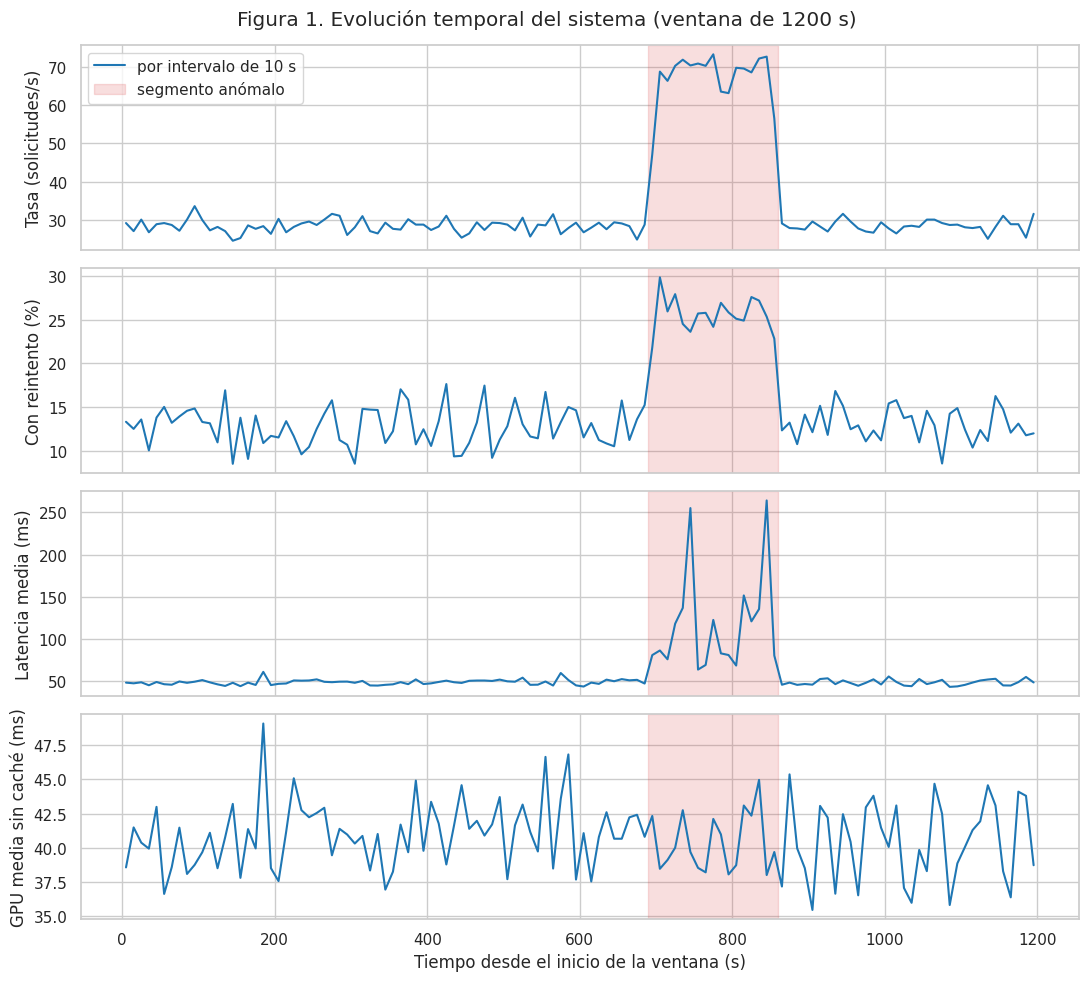

In [23]:
datos["intervalo"] = (datos["t_llegada_s"] // ancho).astype(int)
por_intervalo = datos.groupby("intervalo").agg(
    llegadas=("id_solicitud", "size"),
    reintentos=("intentos", lambda x: (x > 1).mean()),
    latencia=("latencia_ms", "mean"),
)
por_intervalo["gpu"] = datos[datos["cache_hit"] == 0].groupby("intervalo")["gpu_ms"].mean()
tiempo_centro = por_intervalo.index * ancho + ancho / 2  # centro de cada intervalo en s

fig, ejes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
series = [
    (por_intervalo["llegadas"] / ancho, "Tasa (solicitudes/s)"),
    (por_intervalo["reintentos"] * 100, "Con reintento (%)"),
    (por_intervalo["latencia"], "Latencia media (ms)"),
    (por_intervalo["gpu"], "GPU media sin caché (ms)"),
]
for eje, (valores, etiqueta) in zip(ejes, series):
    eje.plot(tiempo_centro, valores, color="tab:blue", label="por intervalo de 10 s")
    eje.axvspan(inicio_anomalo, fin_anomalo, color="tab:red", alpha=0.15, label="segmento anómalo")
    eje.set_ylabel(etiqueta)
ejes[0].legend(loc="upper left")
ejes[-1].set_xlabel("Tiempo desde el inicio de la ventana (s)")
fig.suptitle("Figura 1. Evolución temporal del sistema (ventana de 1200 s)")
plt.tight_layout()
plt.show()

*Pie de Figura 1.* Entre ~690 y ~860 s la tasa de llegadas se dispara, los reintentos casi se duplican y la latencia media sube mucho, pero el tiempo de GPU por solicitud no cambia. El lector debe concluir que el episodio es una ráfaga de tráfico que congestiona la cola, no una GPU más lenta, y que fuera de esa franja el sistema es estable.

**Conclusión A3.** La latencia es la variable que más cambia entre regímenes: en el anómalo su media se duplica con creces y su desviación estándar casi se cuadruplica, por la espera en cola. `gpu_ms`, `red_ms` y `tam_kb` tienen resúmenes casi iguales en ambos regímenes, así que lo que cambia en el episodio anómalo es la carga, no el costo de cada solicitud. `gpu_ms` y `latencia_ms` son muy asimétricas a la derecha y con curtosis alta (colas pesadas); `tam_kb` también es asimétrica, pero menos. `red_ms` es casi simétrica (asimetría y curtosis cercanas a 0), lo que anticipa que podría ser normal (C3). Entre versiones, la B muestra un tiempo medio de GPU unos 4 a 5 ms menor que la A en ambos regímenes, sin diferencias en red ni en tamaño; esto se analiza formalmente en F3.

# Parte B — Llegadas, fallos y reintentos

In [ ]:
estable = datos[datos["regimen"] == "estable"].copy()  # regimen estable de A2
anomalo = datos[datos["regimen"] == "anomalo"].copy()
z = stats.norm.ppf(1 - alpha / 2)  # valor critico para intervalos al nivel 1 - alpha
print("solicitudes en regimen estable:", len(estable), " duracion:", duracion_estable, "s")
print("solicitudes en regimen anomalo:", len(anomalo), " duracion:", duracion_anomalo, "s")
print("nivel de confianza:", confianza, " z =", round(z, 4))

Desde aquí trabajamos con el régimen estable definido en A2: [0, 690) ∪ [860,

1200] s, que dura 1030 s. Creamos las tablas que se usan en el resto del notebook y el valor z del nivel de confianza del grupo.